여러분은 왜 개 사료가 예상보다 빨리 상하게 되는지를 파악하기위해 개 사료 회사에 고용되었습니다. 안 좋은 소식은 이 회사는 한동안 장비를 업그레이드 하지 않았습니다. 즉, 이 회사에서 사용하는 5가지 방부제의 사용 용량이 중구난방이라는 뜻입니다. 하지만 그 중에서 가장 많은 영향을 끼치는 것이 무엇일까요?<br>
이 회사에서는 먼저 4가지 방부제(A, B, C, D)가 함유된 방부제 묶음을 섞은 뒤 '필러'라는 화학물질로 마무리합니다. 식품과학자들은 A, B, C, D 방부제 중 하나가 문제를 일으키고 있다고 생각하지만, 그게 어떤 것인지 명확하게 하기위해 여러분이 고용됐습니다. "랜덤포레스트"로 어떤 방부제가 사료를 빨리 상하게 하는지 찾아보세요!

- Pres_A : 혼합물의 A비율
- Pres_B : 혼합물의 B비율
- Pres_C : 혼합물의 C비율
- Pres_D : 혼합물의 D비율
- Spoiled : 개 사료가 상했는지 여부를 나타내는 레이블.

**시나리오에서 요구하는 바를 고려하여, 머신러닝을 이용해서 문제를 풀어보세요.**

In [31]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import numpy as np

In [2]:
df = pd.read_csv("./과제/랜덤포레스트/dog_food.csv")

In [3]:
df.head()

,A,B,C,D,Spoiled
0,4,2,12.0,3,1.0
1,5,6,12.0,7,1.0
2,6,2,13.0,6,1.0
3,4,2,12.0,1,1.0
4,4,2,12.0,3,1.0


In [8]:
df.describe()

,A,B,C,D,Spoiled
count,490.000000,490.000000,490.000000,490.000000,490.000000
mean,5.534694,5.504082,9.126531,5.579592,0.285714
std,2.951520,2.853797,2.055545,2.854837,0.452216
min,1.000000,1.000000,5.000000,1.000000,0.000000
25%,3.000000,3.000000,8.000000,3.000000,0.000000
50%,5.000000,6.000000,9.000000,6.000000,0.000000
75%,8.000000,8.000000,11.000000,8.000000,1.000000
max,10.000000,10.000000,14.000000,10.000000,1.000000


# 데이터 분석

## boxplot

In [4]:
ndf = df.melt(id_vars = "Spoiled")
ndf.head()

,Spoiled,variable,value
0,1.0,A,4.0
1,1.0,A,5.0
2,1.0,A,6.0
3,1.0,A,4.0
4,1.0,A,4.0


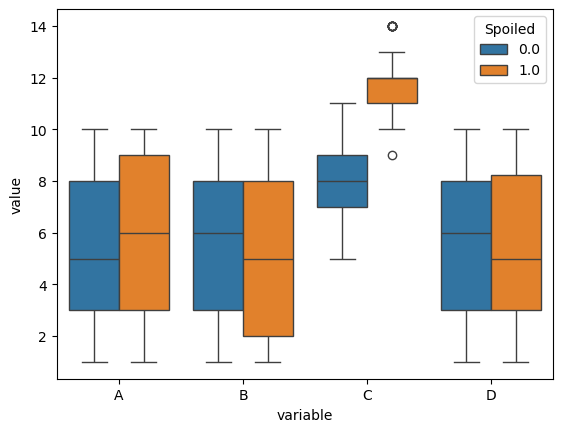

In [6]:
plt.figure()
sns.boxplot(data = ndf, x = "variable", y = "value", hue = "Spoiled")
plt.show()

## pairplot

<Figure size 640x480 with 0 Axes>

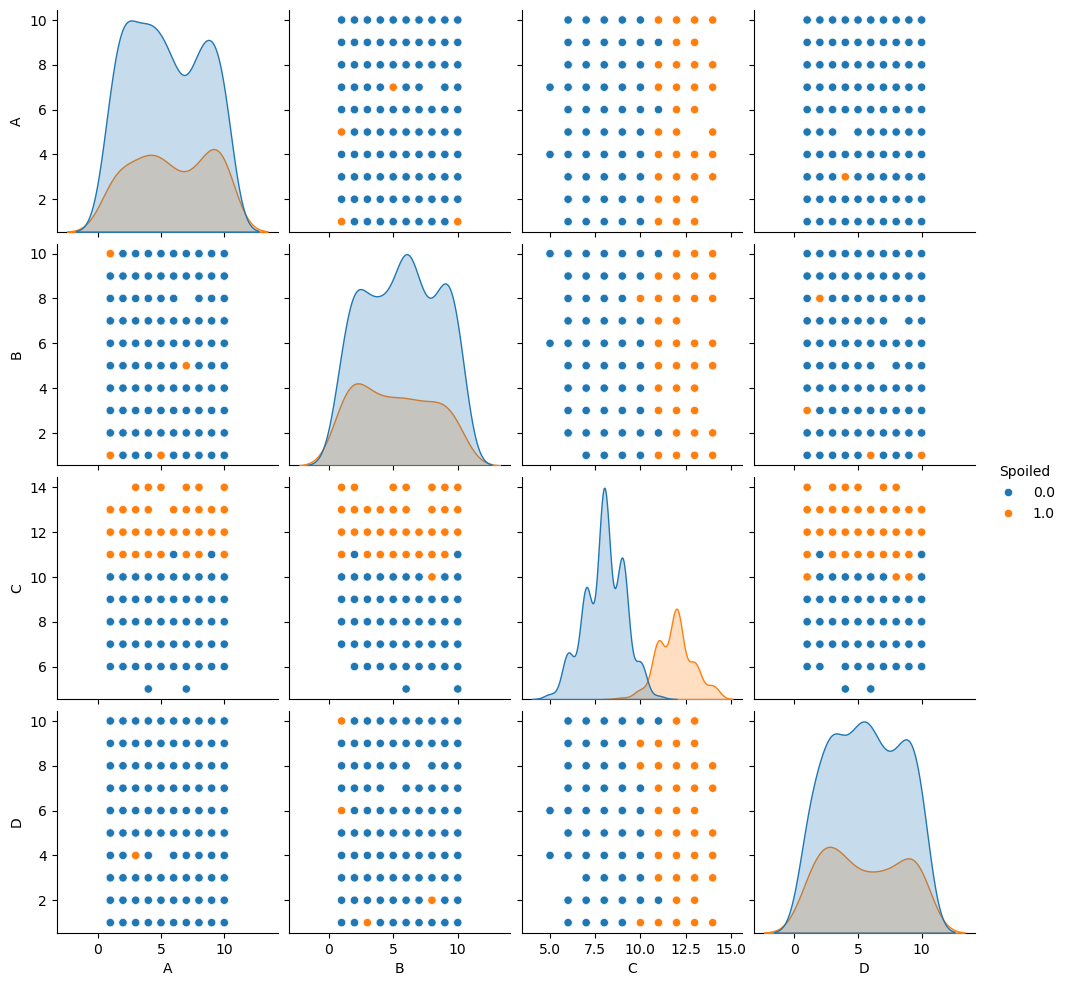

In [7]:
plt.figure()
sns.pairplot(df, hue = "Spoiled")
plt.show()

<Figure size 640x480 with 0 Axes>

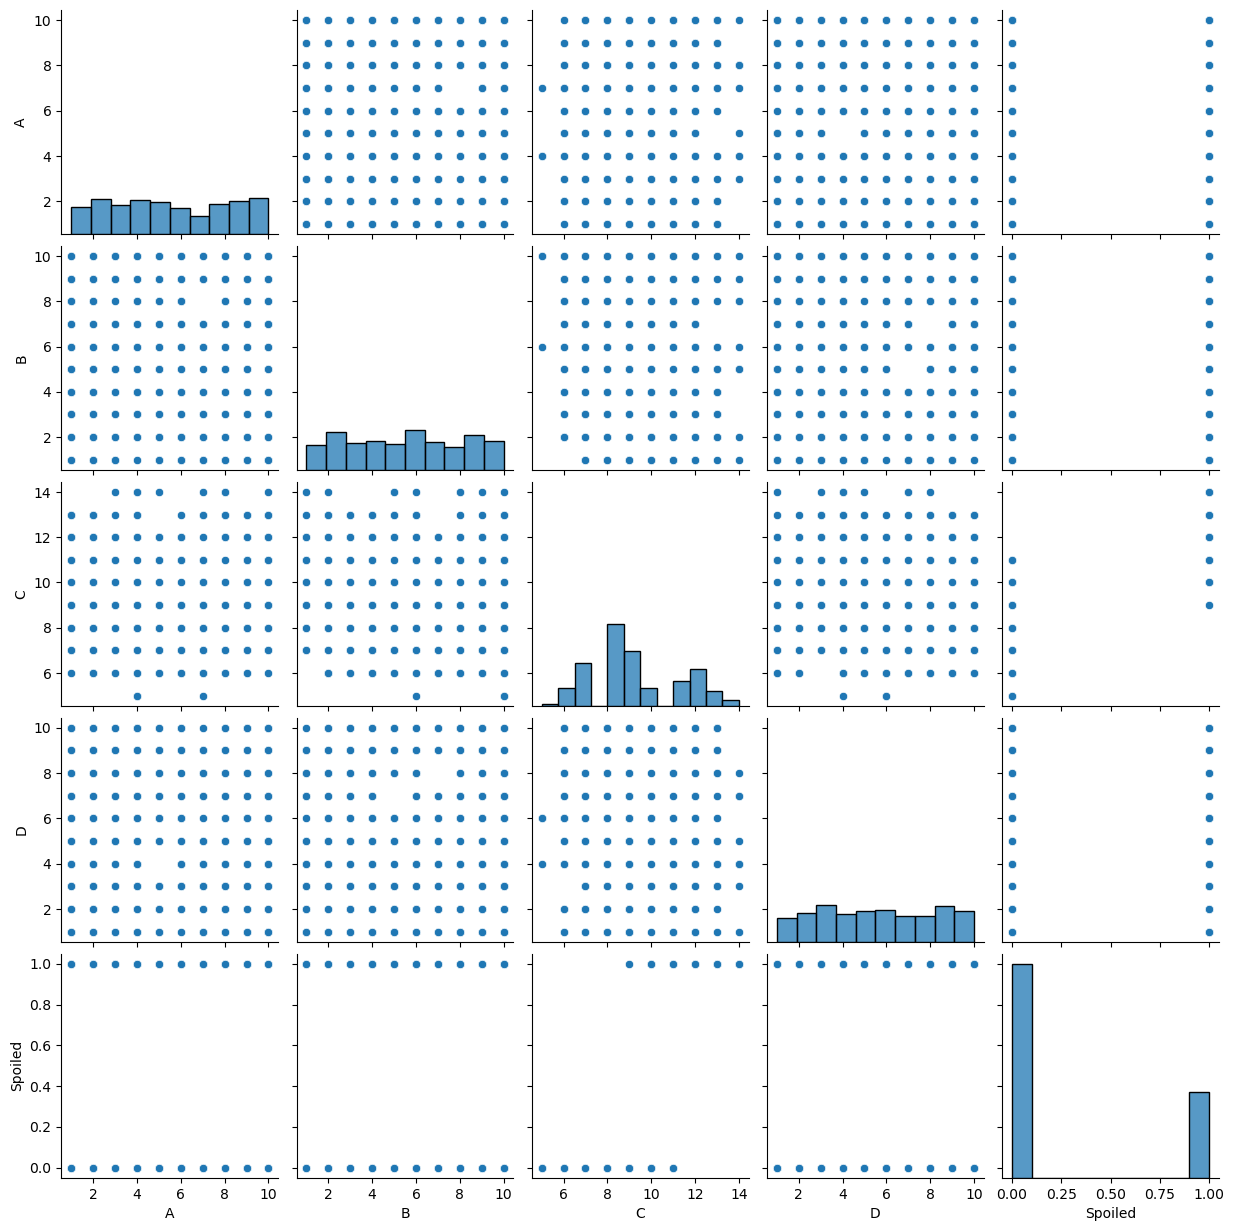

In [33]:
plt.figure()
sns.pairplot(df)
plt.show()

## 통계 검정

In [10]:
spoiled = df[df["Spoiled"] == 1]
normal = df[df["Spoiled"] == 0]

In [11]:
stats.bartlett(spoiled["C"], normal["C"])

BartlettResult(statistic=2.433612464987765, pvalue=0.11875893707243136)

In [12]:
stats.ttest_ind(spoiled["C"], normal["C"], equal_var = True)

TtestResult(statistic=37.00175815922425, pvalue=1.0006887690101255e-143, df=488.0)

## 상관계수

In [13]:
df.corr()

,A,B,C,D,Spoiled
A,1.000000,0.007267,0.057588,-0.045834,0.059973
B,0.007267,1.000000,-0.117222,-0.036436,-0.086474
C,0.057588,-0.117222,1.000000,-0.034477,0.858620
D,-0.045834,-0.036436,-0.034477,1.000000,-0.016067
Spoiled,0.059973,-0.086474,0.858620,-0.016067,1.000000


# 모델

In [14]:
x = df.drop("Spoiled", axis = 1)
y = df["Spoiled"]

In [16]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, stratify = y,
                                                    random_state = 26)

In [17]:
x_train.shape, x_test.shape

((392, 4), (98, 4))

### RandomForest

In [18]:
rf = RandomForestClassifier(n_jobs = -1, random_state = 26)

In [19]:
rf.fit(x_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=26)

In [20]:
rf.score(x_test, y_test)

0.9795918367346939

In [22]:
pred = rf.predict(x_test)

In [23]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99        70
         1.0       0.96      0.96      0.96        28

    accuracy                           0.98        98
   macro avg       0.98      0.98      0.98        98
weighted avg       0.98      0.98      0.98        98



In [24]:
rf.feature_importances_

array([0.03192827, 0.02858564, 0.90340012, 0.03608597])

### LogisticRegression

In [25]:
logi = LogisticRegression()

In [26]:
logi.fit(x_train, y_train)

LogisticRegression()

In [27]:
logi.score(x_test, y_test)

0.9795918367346939

In [28]:
logi.score(x_train, y_train)

0.9821428571428571

In [29]:
logi.coef_

array([[-0.07585524, -0.05000739,  3.39193101,  0.01060048]])

In [32]:
np.exp(logi.coef_)

array([[ 0.92695038,  0.95122239, 29.72329289,  1.01065687]])